# Chuẩn bị dữ liệu ảnh che THẬT để fine-tune

| Bước | Việc | Kết quả |
|---|---|---|
| 1 | Hash mọi ảnh: SHA-256 (trùng y hệt) + pHash/dHash (gần trùng: thu nhỏ, nén lại, đổi định dạng) | `work/hash_cache.json` |
| 2 | So trùng giữa các folder ảnh train với nhau và **với tập test** (`dataset/`, `dataset2/`) | bảng + hình các cụm trùng |
| 3 | Gom về **một folder train**: mỗi cụm trùng giữ 1 ảnh, bỏ ảnh trùng tập test | `data_real_train/` + `manifest.csv` |
| 4 | Gán nhãn **gợi ý** bằng model kết hợp (RF-DETR + probe), xuất file nhập Label Studio | `labelstudio/tasks.json`, `label_config.xml` |
| 5 | (sau khi gán nhãn xong trên Label Studio) chuyển nhãn → COCO, chia train/val theo nhóm | `data_real_train/coco_{train,val}.json` |

Mẫu âm: `NGUON_SACH` mặc định lấy 300 ảnh shop chính hãng phần *train* trong `annotations/store_selection.json` (phần val/test của chúng được coi là tập test).

Có folder ảnh mới (ví dụ của người khác) thì thêm vào `NGUON_CHE` rồi chạy lại từ bước 1. Ảnh đã gán nhãn trên Label Studio vẫn giữ nguyên tên file, nên nhãn cũ không mất.
Kernel: `logo-obstruct (.venv)`.

In [6]:
# ===================== THAM SỐ =====================
import json
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "obstruct_models.py").exists() else Path(r"D:\Code\logo-obstruct-detection")
NGUON_CHE = [                      # folder ảnh CÓ che (thêm folder của người khác vào đây)
    ROOT / "data_real_obstruct",
    ROOT / "data_real_obstruct_2",
]
# Mỗi mục trong NGUON_SACH / THU_MUC_TEST là một folder, HOẶC (tên, [danh sách file]).
# Ảnh shop chính hãng (Adidas / Nike, không che) do select_store_images.py chọn: chỉ phần "train" làm mẫu âm;
# "val" (chọn ngưỡng) và "test" (đếm báo nhầm trong rfdetr_eval.py) đưa vào tập test để ảnh trùng với chúng bị loại khỏi train.
_SHOP = json.loads((ROOT / "annotations" / "store_selection.json").read_text(encoding="utf-8"))
NGUON_SACH = [                     # ảnh KHÔNG che → mẫu âm, không cần gán nhãn
    ("shop_train", _SHOP["train"]),
]
THU_MUC_TEST = [                   # tập test: ảnh trùng với đây sẽ bị LOẠI khỏi train
    ROOT / "dataset", ROOT / "dataset2",
    ("shop_val_test", _SHOP["val"] + _SHOP["test"]),
]
DICH = ROOT / "data_real_train"    # folder gom cuối cùng (sinh tự động, đừng để file tay vào)
LS_DIR = ROOT / "labelstudio"      # file cho Label Studio

NGUONG_PHASH = 8                   # khoảng cách Hamming pHash (64 bit) ≤ ngưỡng → gần trùng
NGUONG_DHASH = 12                  # và dHash ≤ ngưỡng (cả hai cùng thỏa thì mới coi là cùng ảnh)
NGUONG_LECH_SACH = 1.0             # cặp có ảnh SẠCH: thêm điều kiện lệch điểm ảnh trung bình (ảnh xám 32×32, thang 255) ≤ ngưỡng.
                                   # Ảnh shop cùng nền, cùng bố cục nhưng khác sản phẩm hay lọt ngưỡng pHash/dHash (lệch ≥ 1,5);
                                   # bản sao/thu nhỏ thật lệch ≤ 0,2. Ảnh có che giữ nguyên cách so cũ.

GOI_Y_RF, GOI_Y_PROBE = 0.25, 0.8  # bước 4: ngưỡng nới hơn lúc dùng thật → thà gợi ý thừa (xóa nhanh) còn hơn sót (phải vẽ)
GOI_Y_PROBE_RIENG = 0.98           # bước 4: thêm vùng probe rất chắc mà RF-DETR không thấy (vết quẹt cọ…)
TY_LE_VAL = 0.2                    # bước 5: tỉ lệ NHÓM ảnh dùng làm val (chọn checkpoint / ngưỡng)
SO_NGUOI = 2                       # bước 4b: chia ảnh gán nhãn cho bao nhiêu người (labelstudio/nguoi_1 … nguoi_N)
SEED = 0
# ===================================================

In [7]:
import hashlib
import json
import random
import re
import shutil
from collections import defaultdict
from urllib.parse import quote, unquote

import cv2
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

ANH = (".jpg", ".jpeg", ".png", ".webp", ".bmp")
WORK = ROOT / "work"; WORK.mkdir(exist_ok=True)
HASH_CACHE = WORK / "hash_cache.json"


def ds_anh(folder):
    folder = Path(folder)
    return sorted(p for p in folder.rglob("*") if p.suffix.lower() in ANH) if folder.exists() else []


def _bits(a):
    return int("".join("1" if v else "0" for v in a.ravel()), 2)


def hash_anh(p):
    raw = Path(p).read_bytes()
    im = Image.open(p).convert("L"); w, h = im.size
    g = np.asarray(im.resize((32, 32), Image.LANCZOS), np.float32)
    d = cv2.dct(g)[:8, :8]                                     # pHash: 8×8 tần số thấp của DCT
    ph = _bits(d > np.median(d.ravel()[1:]))                  # bỏ thành phần DC khi lấy trung vị
    s = np.asarray(im.resize((9, 8), Image.LANCZOS), np.int16)
    dh = _bits(s[:, 1:] > s[:, :-1])                          # dHash: so sánh điểm ảnh liền kề
    return {"sha256": hashlib.sha256(raw).hexdigest(), "phash": f"{ph:016x}", "dhash": f"{dh:016x}", "w": w, "h": h}


def ham(a, b):
    return bin(int(a, 16) ^ int(b, 16)).count("1")

## Bước 1: hash mọi ảnh

In [8]:
cache = json.loads(HASH_CACHE.read_text(encoding="utf-8")) if HASH_CACHE.exists() else {}
REC = []   # mỗi ảnh: path, vai trò (che / sach / test), nguồn, hash
for role, folders in (("che", NGUON_CHE), ("sach", NGUON_SACH), ("test", THU_MUC_TEST)):
    for f in folders:
        if isinstance(f, tuple):                  # (tên, [danh sách file])
            ten, ds = f
            files = [Path(x) for x in ds if Path(x).exists()]
            if len(files) < len(ds):
                print(f"   CẢNH BÁO {ten}: thiếu {len(ds) - len(files)}/{len(ds)} file (máy này không có folder ảnh gốc?)")
        else:
            ten, files = Path(f).name, ds_anh(f)
            if not Path(f).exists():
                print(f"   CẢNH BÁO: không có folder {f}")
        print(f"{role:5s} {ten}: {len(files)} ảnh")
        for p in files:
            st = p.stat(); key = f"{p}|{st.st_size}|{int(st.st_mtime)}"
            if key not in cache:
                try:
                    cache[key] = hash_anh(p)
                except Exception as e:
                    print(f"   bỏ qua (không đọc được): {p.name} · {type(e).__name__}")
                    continue
            REC.append({"path": p, "role": role, "nguon": ten, **cache[key]})
HASH_CACHE.write_text(json.dumps(cache), encoding="utf-8")
print(f"Tổng {len(REC)} ảnh đã hash")

che   D:\Code\logo-obstruct-detection\data_real_obstruct: 49 ảnh
che   D:\Code\logo-obstruct-detection\data_real_obstruct_2: 178 ảnh
test  D:\Code\logo-obstruct-detection\dataset: 24 ảnh
test  D:\Code\logo-obstruct-detection\dataset2: 20 ảnh
Tổng 271 ảnh đã hash


## Bước 2: so trùng (trùng y hệt và gần trùng)
Gom các ảnh trùng thành **cụm** (union-find). Mỗi cụm cho biết:
- **trùng test**: cụm có ảnh của `dataset/` hoặc `dataset2/`. Ảnh train trong cụm sẽ bị **loại** để tập test còn sạch;
- **trùng nội bộ**: nhiều ảnh train cùng một ảnh, chỉ giữ 1 (độ phân giải lớn nhất);
- **che/sạch lẫn nhau**: cùng một ảnh nằm ở cả folder có che và folder sạch, cần xem lại.

30 cụm trùng:
  cụm 0 · TRÙNG TEST → loại khỏi train · giống hệt:
     [che ] data_real_obstruct/vn-11134201-81ztc-mu3tmvve8buu1d.webp (894×894)
     [test] dataset2/vn-11134201-81ztc-mu3tmvve8buu1d.webp (894×894)
  cụm 1 · trùng nội bộ → giữ 1 · giống hệt:
     [che ] data_real_obstruct/vn-11134207-7ras8-mc7ef1q7cvkl0c@resize_w900_nl.webp (750×750)
     [che ] data_real_obstruct_2/vn-11134207-7ras8-mc7ef1q7cvkl0c.webp (750×750)
  cụm 2 · trùng nội bộ → giữ 1 · gần trùng:
     [che ] data_real_obstruct/vn-11134207-81ztc-mosi5i81yz9rc2@resize_w900_nl.webp (900×900)
     [che ] data_real_obstruct_2/vn-11134201-81ztc-mu3e8scbhrep42.webp (1024×1024)
  cụm 3 · trùng nội bộ → giữ 1 · giống hệt:
     [che ] data_real_obstruct/vn-11134207-81ztc-mpktqkvvkyryf0@resize_w900_nl.webp (764×764)
     [che ] data_real_obstruct_2/vn-11134207-81ztc-mpktqkvvkyryf0.webp (764×764)
  cụm 4 · trùng nội bộ → giữ 1 · giống hệt:
     [che ] data_real_obstruct/vn-11134207-820l4-mect4rnlu29vab@resize_w900_nl (1).

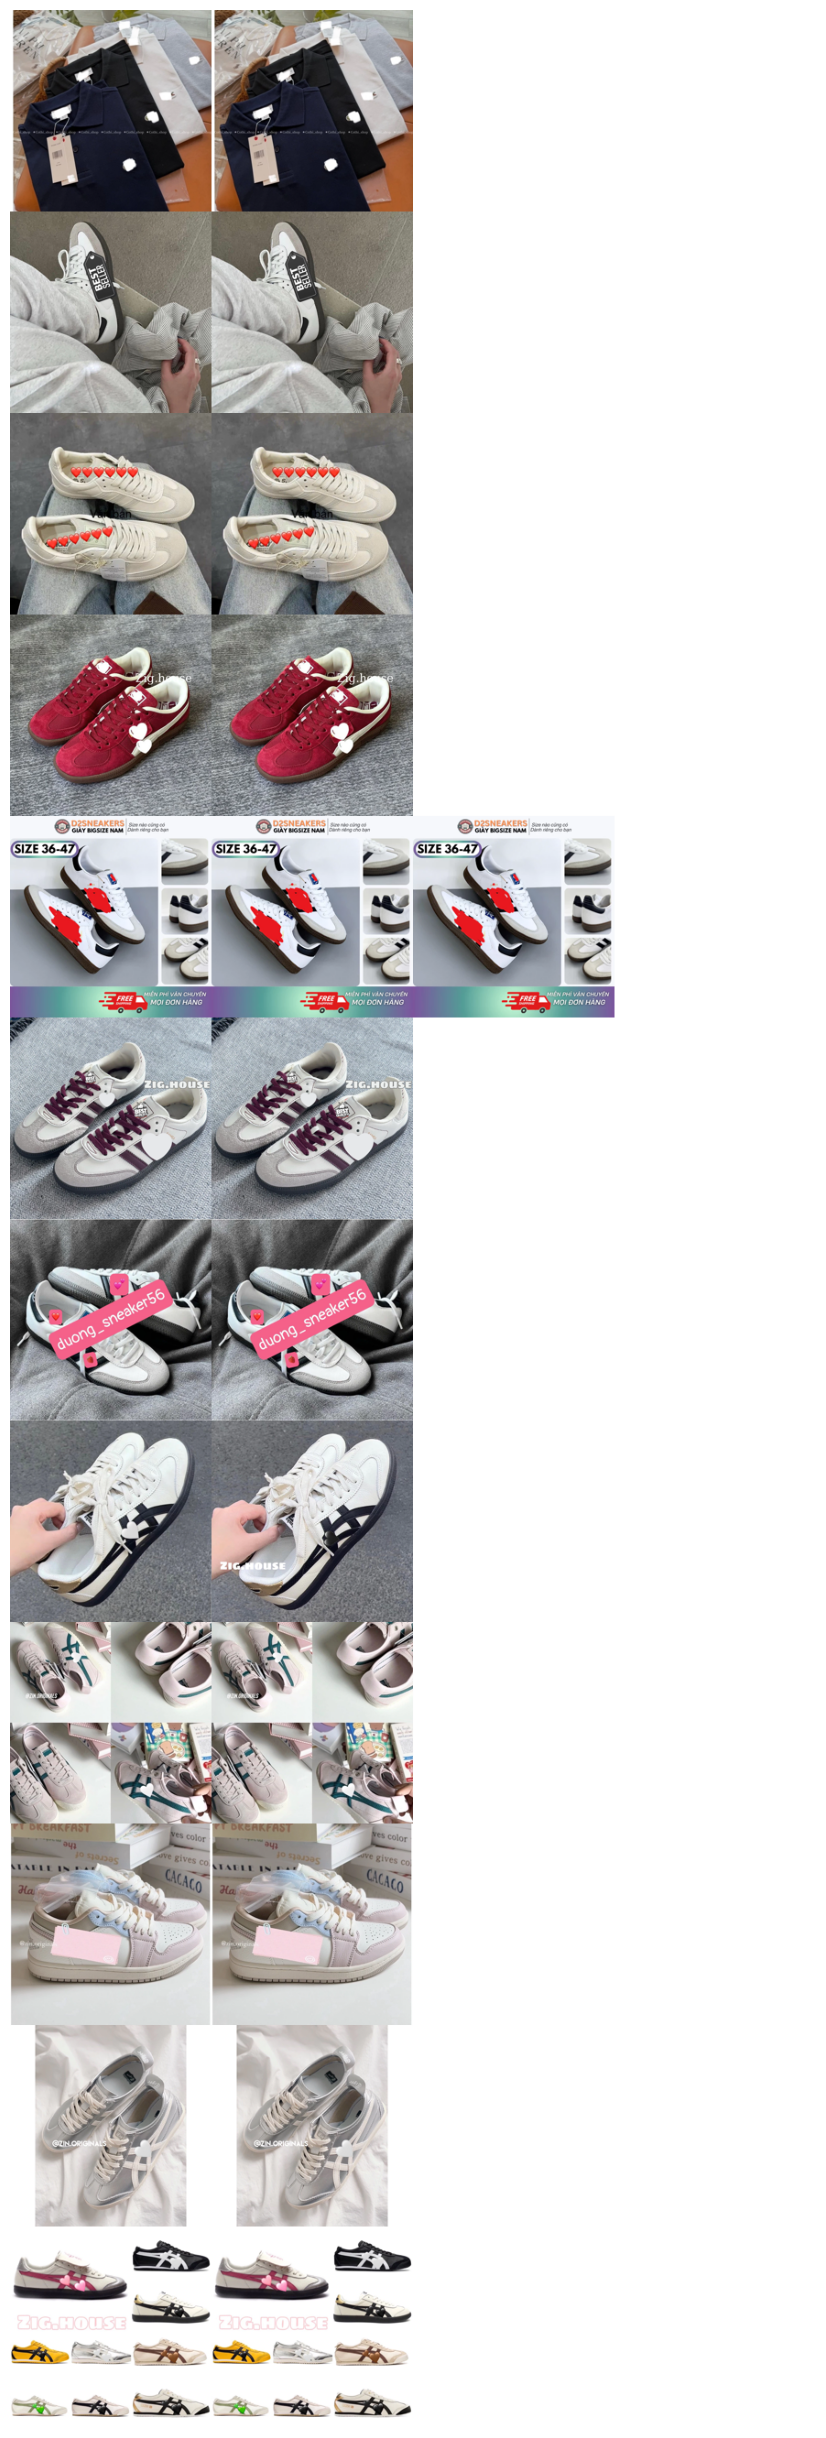

In [9]:
par = list(range(len(REC)))


def find(i):
    while par[i] != i:
        par[i] = par[par[i]]; i = par[i]
    return i


def union(i, j):
    par[find(i)] = find(j)


by_sha = defaultdict(list)
for i, r in enumerate(REC):
    by_sha[r["sha256"]].append(i)
for ids in by_sha.values():
    for j in ids[1:]:
        union(ids[0], j)
_xam = {}


def lech_diem_anh(i, j):
    for k in (i, j):
        if k not in _xam:
            _xam[k] = np.asarray(Image.open(REC[k]["path"]).convert("L").resize((32, 32), Image.LANCZOS), np.float32)
    return float(np.abs(_xam[i] - _xam[j]).mean())


n_loai_gia = 0
for i in range(len(REC)):
    for j in range(i + 1, len(REC)):
        if ham(REC[i]["phash"], REC[j]["phash"]) <= NGUONG_PHASH and ham(REC[i]["dhash"], REC[j]["dhash"]) <= NGUONG_DHASH:
            if "sach" in (REC[i]["role"], REC[j]["role"]) and lech_diem_anh(i, j) > NGUONG_LECH_SACH:
                n_loai_gia += 1; continue          # cùng bố cục nhưng khác ảnh (thường gặp ở ảnh shop nền trơn)
            union(i, j)
print(f"bỏ qua {n_loai_gia} cặp gần trùng giả có ảnh sạch (lệch điểm ảnh > {NGUONG_LECH_SACH})")
cum = defaultdict(list)
for i in range(len(REC)):
    cum[find(i)].append(i)
CUM_TRUNG = [ids for ids in cum.values() if len(ids) > 1]
for k, ids in enumerate(CUM_TRUNG):
    for i in ids:
        REC[i]["cum"] = k
print(f"{len(CUM_TRUNG)} cụm trùng:")
for k, ids in enumerate(CUM_TRUNG):
    roles = {REC[i]["role"] for i in ids}
    loai = ("trùng trong tập test (không ảnh hưởng train)" if roles == {"test"} else "TRÙNG TEST → loại khỏi train" if "test" in roles
            else "che/sạch lẫn nhau → xem lại" if {"che", "sach"} <= roles else "trùng nội bộ → giữ 1")
    giong_het = len({REC[i]["sha256"] for i in ids}) == 1
    print(f"  cụm {k} · {loai} · {'giống hệt' if giong_het else 'gần trùng'}:")
    for i in ids:
        r = REC[i]
        print(f"     [{r['role']:4s}] {r['nguon']}/{r['path'].name} ({r['w']}×{r['h']})")


def xem_cum(ids_list, cols=4):
    rows = []
    for ids in ids_list:
        ims = []
        for i in ids[:cols]:
            im = Image.open(REC[i]["path"]).convert("RGB"); im.thumbnail((220, 220))
            t = Image.new("RGB", (220, 220), "white"); t.paste(im, (0, 0)); ims.append(np.asarray(t))
        while len(ims) < cols:
            ims.append(np.full((220, 220, 3), 255, np.uint8))
        rows.append(np.hstack(ims))
    if rows:
        plt.figure(figsize=(cols * 2.6, len(rows) * 2.7)); plt.imshow(np.vstack(rows)); plt.axis("off"); plt.show()


xem_cum(CUM_TRUNG[:12])

## Bước 3: gom về một folder train
- Ảnh trùng tập test: **bỏ**.
- Cụm trùng nội bộ: giữ ảnh độ phân giải lớn nhất.
- Ảnh giữ tên file gốc (trùng tên giữa các nguồn thì thêm tiền tố tên nguồn), nhờ vậy nhãn Label Studio cũ vẫn khớp khi chạy lại.
- Ảnh sạch (mẫu âm, ví dụ ảnh shop chính hãng) chép vào `sach/`, không cần gán nhãn. Ảnh shop cùng cụm mã sản phẩm chung một nhóm.
- `nhom`: dùng để chia train/val sao cho ảnh **cùng shop** không nằm cả hai bên. Tên file Shopee/Facebook không cho biết shop, nên mặc định mỗi ảnh là một nhóm. **Nên điền tên shop vào cột `nhom` trong `data_real_train/manifest.csv`** (giá trị này được giữ lại khi chạy lại bước 3).

In [10]:
def doan_nhom(name):
    s = Path(name).stem
    # ảnh shop (tên là mã số): cùng cụm mã sản phẩm (mã // 1000) = cùng nhóm, giống cách chia trong select_store_images.py
    return f"ma_{s[:-3]}" if s.isdigit() and len(s) > 6 else s


keep, bo = [], []
for ids in cum.values():
    train_ids = [i for i in ids if REC[i]["role"] in ("che", "sach")]
    if not train_ids:
        continue
    if any(REC[i]["role"] == "test" for i in ids):
        bo += [(i, "trùng tập test") for i in train_ids]; continue
    # ưu tiên: ảnh có che > độ phân giải lớn > tên không có hậu tố " (1)" / tên ngắn hơn
    best = max(train_ids, key=lambda i: (REC[i]["role"] == "che", REC[i]["w"] * REC[i]["h"],
                                         not re.search(r" \(\d+\)$", REC[i]["path"].stem), -len(REC[i]["path"].name)))
    keep.append(best)
    bo += [(i, f"trùng với {REC[best]['path'].name}") for i in train_ids if i != best]

old_manifest = {}
if (DICH / "manifest.csv").exists():
    import csv
    with open(DICH / "manifest.csv", encoding="utf-8") as fh:
        old_manifest = {r["file"]: r for r in csv.DictReader(fh)}
for sub in ("images", "sach"):
    if (DICH / sub).exists():
        shutil.rmtree(DICH / sub)
    (DICH / sub).mkdir(parents=True)
rows, used = [], set()
for i in sorted(keep, key=lambda i: str(REC[i]["path"])):
    r = REC[i]; sub = "images" if r["role"] == "che" else "sach"
    name = r["path"].name
    if (sub, name) in used:
        name = f"{r['nguon']}__{name}"
    used.add((sub, name))
    shutil.copy2(r["path"], DICH / sub / name)
    rel = f"{sub}/{name}"
    rows.append({"file": rel, "loai": r["role"], "nguon": r["nguon"], "file_goc": str(r["path"]),
                 "nhom": old_manifest.get(rel, {}).get("nhom") or doan_nhom(name),
                 "w": r["w"], "h": r["h"], "sha256": r["sha256"], "phash": r["phash"]})
import csv
with open(DICH / "manifest.csv", "w", encoding="utf-8", newline="") as fh:
    wr = csv.DictWriter(fh, fieldnames=list(rows[0].keys())); wr.writeheader(); wr.writerows(rows)
with open(DICH / "bo_qua.csv", "w", encoding="utf-8", newline="") as fh:
    wr = csv.writer(fh); wr.writerow(["file_goc", "ly_do"])
    for i, why in bo:
        wr.writerow([str(REC[i]["path"]), why])
print(f"Giữ {len(rows)} ảnh → {DICH} (có che {sum(r['loai'] == 'che' for r in rows)}, sạch {sum(r['loai'] == 'sach' for r in rows)}) · "
      f"bỏ {len(bo)} ảnh (xem bo_qua.csv) · {len({r['nhom'] for r in rows})} nhóm")
for i, why in bo:
    print(f"   bỏ: {REC[i]['nguon']}/{REC[i]['path'].name} · {why}")

Giữ 197 ảnh → D:\Code\logo-obstruct-detection\data_real_train (có che 197, sạch 0) · bỏ 30 ảnh (xem bo_qua.csv) · 197 nhóm
   bỏ: data_real_obstruct/vn-11134201-81ztc-mu3tmvve8buu1d.webp · trùng tập test
   bỏ: data_real_obstruct/vn-11134207-7ras8-mc7ef1q7cvkl0c@resize_w900_nl.webp · trùng với vn-11134207-7ras8-mc7ef1q7cvkl0c.webp
   bỏ: data_real_obstruct/vn-11134207-81ztc-mosi5i81yz9rc2@resize_w900_nl.webp · trùng với vn-11134201-81ztc-mu3e8scbhrep42.webp
   bỏ: data_real_obstruct/vn-11134207-81ztc-mpktqkvvkyryf0@resize_w900_nl.webp · trùng với vn-11134207-81ztc-mpktqkvvkyryf0.webp
   bỏ: data_real_obstruct/vn-11134207-820l4-mect4rnlu29vab@resize_w900_nl (1).webp · trùng với vn-11134207-820l4-mect4rnlu29vab.webp
   bỏ: data_real_obstruct/vn-11134207-820l4-mect4rnlu29vab@resize_w900_nl.webp · trùng với vn-11134207-820l4-mect4rnlu29vab.webp
   bỏ: data_real_obstruct/vn-11134207-820l4-mf1cao434zka94@resize_w900_nl.webp · trùng với vn-11134207-820l4-mf1cao434zka94.webp
   bỏ: data_real_o

## Bước 4: gán nhãn gợi ý → Label Studio
Model kết hợp chạy trên ảnh **có che** của `data_real_train/images/`. Ngưỡng nới hơn lúc dùng thật, vì xóa một khung thừa nhanh hơn vẽ một khung bị sót. Thêm vùng mà probe rất chắc (≥ 0,98) nhưng RF-DETR bỏ qua.
Ảnh trong `sach/` không cần gán nhãn: chúng vào train như ảnh không có khung.

In [11]:
import sys

sys.path.insert(0, str(ROOT))
from obstruct_models import Models, iou

M = Models(probe=True, rfdetr=True)
LS_DIR.mkdir(exist_ok=True)
tasks, n_box = [], 0
for r in [r for r in rows if r["loai"] == "che"]:
    p = DICH / r["file"]
    img = M.load(p); W0, H0 = int(r["w"]), int(r["h"]); s = W0 / img.shape[1]
    heat = M.heat(img)
    vung = [dict(k, nguon="ket_hop") for k in M.ket_hop(img, GOI_Y_RF, GOI_Y_PROBE, heat=heat)]
    for k in M.boxes_from_heat(heat, GOI_Y_PROBE_RIENG):
        if all(iou(k["bbox"], v["bbox"]) == 0 for v in vung):
            vung.append(dict(k, nguon="probe"))
    res = []
    for j, v in enumerate(vung):
        x0, y0, x1, y1 = [c * s for c in v["bbox"]]
        res.append({"id": f"g{j}", "from_name": "label", "to_name": "image", "type": "rectanglelabels",
                    "original_width": W0, "original_height": H0, "image_rotation": 0,
                    "score": float(v.get("diem_rfdetr", v.get("diem_probe", 0))),
                    "value": {"x": 100 * x0 / W0, "y": 100 * y0 / H0, "width": 100 * (x1 - x0) / W0,
                              "height": 100 * (y1 - y0) / H0, "rotation": 0, "rectanglelabels": ["obstruction"]}})
    n_box += len(res)
    tasks.append({"data": {"image": "/data/local-files/?d=" + quote(f"{DICH.name}/{r['file']}"), "file": r["file"], "nhom": r["nhom"]},
                  "predictions": [{"model_version": "ket_hop_rfdetr+probe", "score": max([x["score"] for x in res], default=0.0),
                                   "result": res}]})
(LS_DIR / "tasks.json").write_text(json.dumps(tasks, ensure_ascii=False, indent=1), encoding="utf-8")
(LS_DIR / "label_config.xml").write_text("""<View>
  <Header value="Khoanh VÙNG CHE (sticker, tô trơn, quẹt cọ, làm mờ, xóa chữ nhãn, chữ đè lên logo). KHÔNG khoanh: watermark shop, banner ngoài sản phẩm, logo in thật, mác treo còn nguyên."/>
  <Image name="image" value="$image" zoom="true" zoomControl="true"/>
  <RectangleLabels name="label" toName="image">
    <Label value="obstruction" background="#ff00ff"/>
  </RectangleLabels>
  <Choices name="kind" toName="image" perRegion="true" showInline="true">
    <Choice value="sticker"/><Choice value="paint"/><Choice value="blur"/><Choice value="text_overlay"/>
  </Choices>
  <Choices name="trang_thai" toName="image" showInline="true">
    <Choice value="bỏ ảnh này"/>
  </Choices>
</View>
""", encoding="utf-8")
print(f"{len(tasks)} ảnh · {n_box} khung gợi ý → {LS_DIR / 'tasks.json'}")

d:\Code\logo-obstruct-detection\.venv\Lib\site-packages\albumentations\__init__.py:24: UserWarning: A new version of Albumentations is available: 2.0.8 (you have 1.4.24). Upgrade using: pip install -U albumentations. To disable automatic update checks, set the environment variable NO_ALBUMENTATIONS_UPDATE to 1.
  check_for_updates()
[2026-11-17 09:19:16] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-11-17 09:19:16] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.


[2026-11-17 09:19:16] [INFO] rf-detr - Loading pretrain weights


[2026-11-17 09:19:16] [WARNING] rf-detr - Reinitializing detection head with 1 classes based on pretrained weights, configured for 90.
[2026-11-17 09:19:17] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. You can optimize the model for inference by calling model.optimize_for_inference().


197 ảnh · 647 khung gợi ý → D:\Code\logo-obstruct-detection\labelstudio\tasks.json


## Bước 4b: chia việc gán nhãn cho nhiều người
Mỗi người nhận một folder `labelstudio/nguoi_k/` gồm `images/` (bản sao ảnh) và `tasks.json` (ảnh + khung gợi ý). Ảnh cùng `nhom` luôn về cùng một người. Khối lượng được cân theo số khung gợi ý (ảnh nhiều khung thì sửa lâu hơn).
**Chạy lại ô này sẽ xóa và tạo lại `labelstudio/nguoi_*/images` và `tasks.json`**, nhưng giữ `export.json` nếu đã có. Chỉ chạy lại khi muốn chia lại từ đầu.

In [ ]:
CHIA = json.loads((LS_DIR / "tasks.json").read_text(encoding="utf-8"))
nhom_tasks = defaultdict(list)
for t in CHIA:
    nhom_tasks[t["data"].get("nhom") or t["data"]["file"]].append(t)
viec = lambda ts: sum(1 + len(t["predictions"][0]["result"]) for t in ts)   # 1 ảnh + số khung gợi ý
tai = [0] * SO_NGUOI
phan = [[] for _ in range(SO_NGUOI)]
for nhom, ts in sorted(nhom_tasks.items(), key=lambda kv: (-viec(kv[1]), kv[0])):
    k = tai.index(min(tai)); phan[k] += ts; tai[k] += viec(ts)
for k, ts in enumerate(phan, 1):
    d = LS_DIR / f"nguoi_{k}"
    if (d / "images").exists():
        shutil.rmtree(d / "images")
    (d / "images").mkdir(parents=True)
    out = []
    for t in sorted(ts, key=lambda t: t["data"]["file"]):
        name = Path(t["data"]["file"]).name
        shutil.copy2(DICH / t["data"]["file"], d / "images" / name)
        t2 = json.loads(json.dumps(t))
        t2["data"]["image"] = "/data/local-files/?d=" + quote(f"{LS_DIR.name}/nguoi_{k}/images/{name}")
        t2["data"]["nguoi"] = f"nguoi_{k}"
        out.append(t2)
    (d / "tasks.json").write_text(json.dumps(out, ensure_ascii=False, indent=1), encoding="utf-8")
    print(f"nguoi_{k}: {len(out)} ảnh · {sum(len(t['predictions'][0]['result']) for t in out)} khung gợi ý → {d}")

### Gán nhãn trên Label Studio (mỗi người làm trên folder của mình)
Cài đặt: xem `README.md` (venv riêng `.venv-labelstudio`). Mở PowerShell **tại thư mục gốc của repo** rồi chạy:
```
$env:LABEL_STUDIO_LOCAL_FILES_SERVING_ENABLED = "true"
$env:LABEL_STUDIO_LOCAL_FILES_DOCUMENT_ROOT = (Get-Location).Path
.\.venv-labelstudio\Scripts\label-studio.exe start --port 8080 --internal-host localhost
```
1. Đợi khoảng 1 phút (lần đầu tạo cơ sở dữ liệu), mở http://localhost:8080, tạo tài khoản (chỉ lưu trên máy).
2. **Create Project** → tab *Labeling Setup* → *Code* → dán nội dung `labelstudio/label_config.xml`.
3. *Settings* → *Cloud Storage* → *Add Source Storage* → **Local files**, *Absolute local path* = `<thư mục repo>\labelstudio
guoi_k\images` (k là số của bạn), **tắt** *Treat every bucket object as a source file* → *Add Storage* (**không** bấm *Sync*). Bước này chỉ cấp quyền đọc ảnh.
4. **Import** → chọn `labelstudio/nguoi_k/tasks.json`. Mỗi ảnh có sẵn khung gợi ý.
5. Gán nhãn theo quy tắc trong `README.md`: sửa, xóa hoặc vẽ thêm khung; chọn kiểu che cho từng khung nếu được. Ảnh hỏng hoặc không liên quan thì chọn **bỏ ảnh này**. Bấm *Submit* cho từng ảnh (kể cả ảnh không còn khung nào).
6. **Export** → **JSON** → lưu đúng tên `labelstudio/nguoi_k/export.json` → commit và push lên GitHub.

## Bước 5: gộp nhãn của mọi người → COCO, chia train/val theo nhóm
- Đọc mọi `labelstudio/nguoi_*/export.json` (và `labelstudio/export.json` nếu có). Một ảnh có nhiều bản nhãn thì lấy bản sửa sau cùng.
- Chỉ lấy ảnh đã *Submit*. Ảnh chọn "bỏ ảnh này" bị bỏ.
- Ảnh trong `sach/` vào train/val như ảnh không có khung (mẫu âm).
- Chia theo `nhom` (cột trong `manifest.csv`): ảnh cùng nhóm luôn nằm cùng một bên.
- Cần có `data_real_train/images/`: nếu vừa clone repo thì chạy bước 1–3 trước (không cần model).

In [12]:
EXPORTS = sorted(LS_DIR.glob("nguoi_*/export.json")) + ([LS_DIR / "export.json"] if (LS_DIR / "export.json").exists() else [])
if not EXPORTS:
    print(f"Chưa có export nào trong {LS_DIR}/nguoi_*/export.json: gán nhãn trên Label Studio rồi export JSON vào đó.")
else:
    ex = []
    for e in EXPORTS:
        part = json.loads(e.read_text(encoding="utf-8")); ex += part
        print(f"{e.relative_to(ROOT)}: {len(part)} ảnh")
    # một ảnh có thể xuất hiện ở nhiều export: giữ bản có annotation sửa sau cùng
    def _moi_nhat(t):
        return max([a.get("updated_at") or a.get("created_at") or "" for a in t.get("annotations", []) if not a.get("was_cancelled")], default="")
    gop = {}
    for t in ex:
        f = t["data"].get("file") or unquote(t["data"]["image"].split("?d=", 1)[1]).split("/", 1)[1]
        if f not in gop or _moi_nhat(t) > _moi_nhat(gop[f]):
            gop[f] = t
    ex = list(gop.values())
    man = {r["file"]: r for r in csv.DictReader(open(DICH / "manifest.csv", encoding="utf-8"))}
    lab, bo_anh, chua = {}, 0, 0
    for t in ex:
        f = t["data"].get("file") or unquote(t["data"]["image"].split("?d=", 1)[1]).split("/", 1)[1]
        anns = [a for a in t.get("annotations", []) if not a.get("was_cancelled")]
        if not anns:
            chua += 1; continue
        a = max(anns, key=lambda a: a.get("updated_at") or a.get("created_at") or "")
        if any(r.get("from_name") == "trang_thai" and "bỏ ảnh này" in r["value"].get("choices", []) for r in a["result"]):
            bo_anh += 1; continue
        kinds = {r["id"]: r["value"]["choices"][0] for r in a["result"] if r.get("from_name") == "kind" and r["value"].get("choices")}
        boxes = []
        for r in a["result"]:
            if r.get("type") != "rectanglelabels":
                continue
            W, H, v = r["original_width"], r["original_height"], r["value"]
            boxes.append({"bbox": [v["x"] * W / 100, v["y"] * H / 100, v["width"] * W / 100, v["height"] * H / 100],
                          "kind": kinds.get(r["id"], "")})
        lab[f] = boxes
    for f, r in man.items():
        if r["loai"] == "sach":
            lab[f] = []
    nhoms = sorted({man[f]["nhom"] for f in lab})
    random.Random(SEED).shuffle(nhoms)
    n_val = max(1, round(len(nhoms) * TY_LE_VAL)) if len(nhoms) > 1 else 0
    val_nhom = set(nhoms[:n_val])
    for split in ("train", "val"):
        coco = {"images": [], "annotations": [], "categories": [{"id": 0, "name": "obstruction", "supercategory": "none"}]}
        for f in sorted(lab):
            if (man[f]["nhom"] in val_nhom) != (split == "val"):
                continue
            iid = len(coco["images"])
            coco["images"].append({"id": iid, "file_name": f, "width": int(man[f]["w"]), "height": int(man[f]["h"])})
            for b in lab[f]:
                coco["annotations"].append({"id": len(coco["annotations"]), "image_id": iid, "category_id": 0, "bbox": b["bbox"],
                                            "area": b["bbox"][2] * b["bbox"][3], "iscrowd": 0, "attributes": {"kind": b["kind"]}})
        (DICH / f"coco_{split}.json").write_text(json.dumps(coco, ensure_ascii=False), encoding="utf-8")
        print(f"{split}: {len(coco['images'])} ảnh ({sum(1 for im in coco['images'] if man[im['file_name']]['loai'] == 'sach')} sạch), "
              f"{len(coco['annotations'])} khung")
    print(f"chưa gán nhãn: {chua} · bỏ: {bo_anh} · nhóm val: {sorted(val_nhom)}")
    print("Train: .venv\\Scripts\\python.exe -X utf8 rfdetr_train.py --real data_real_train --init work/rfdetr_out/checkpoint_best_total.pth")

labelstudio\nguoi_1\export.json: 98 ảnh
labelstudio\nguoi_2\export.json: 99 ảnh
train: 158 ảnh (0 sạch), 450 khung
val: 39 ảnh (0 sạch), 130 khung
chưa gán nhãn: 0 · bỏ: 0 · nhóm val: ['883383712_122122505985505766_8446547377182373628_n', 'c47ffcba-8152-4571-bdb4-a56e6e41bd11', 'sg-11134202-82598-mt4snyfzvnk7e7', 'vn-11134201-81ztc-msasfjlkxr7ke2', 'vn-11134201-81ztc-msedrbb83hmxa7@resize_w900_nl', 'vn-11134201-81ztc-mswvmmvg5y4l98', 'vn-11134201-81ztc-mswvmn2dewavc7', 'vn-11134201-81ztc-mtbqrbb3j6rpf5', 'vn-11134201-81ztc-muhcn3cbpxc0a6', 'vn-11134207-7ra0g-m7mhakm7jd6rd4', 'vn-11134207-7ra0g-m7pewk3etksj30@resize_w900_nl', 'vn-11134207-7ras8-m5xs20me3pc3b0', 'vn-11134207-7ras8-mcex6m8je5wjb2', 'vn-11134207-81ztc-mk99n1fuujgga0', 'vn-11134207-81ztc-mk9qass86ps297', 'vn-11134207-81ztc-mkbcryxu30n7fd', 'vn-11134207-81ztc-mm8gwrhu0s204c', 'vn-11134207-81ztc-mm8gwrhu97gk24', 'vn-11134207-81ztc-mm8gwrhxnev6fc', 'vn-11134207-81ztc-mmqzxbzyshz7fe', 'vn-11134207-81ztc-mmvihx1ey3gh9e', 'vn-111